# Session 4: Convolutional Neural Networks and Filters

This notebook contains structured tasks based on Session 4 materials.

**Instructions:**
- Do NOT use a separate `.py` file. Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- For Visulaization, please use `%matplotlib inline`
- Submit your completed notebook by uploading it to your forked repository.

### ***DO NOT UPLOAD THE DATASET TO GITHUB as it's too large***
<hr>

## Task 1: Convolutional Filters on an Image
Apply several 2D filters (Sobel X, Sobel Y, Laplacian, and Sharpen) to an image and visualize the results side by side.

**Hint:**
- Use OpenCV (`cv2.filter2D`) or NumPy to apply kernels.
- Define common kernels (Sobel, Laplacian, Sharpen).
- Use `matplotlib.pyplot` to plot the original and filtered images.

In [3]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import torch 
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F

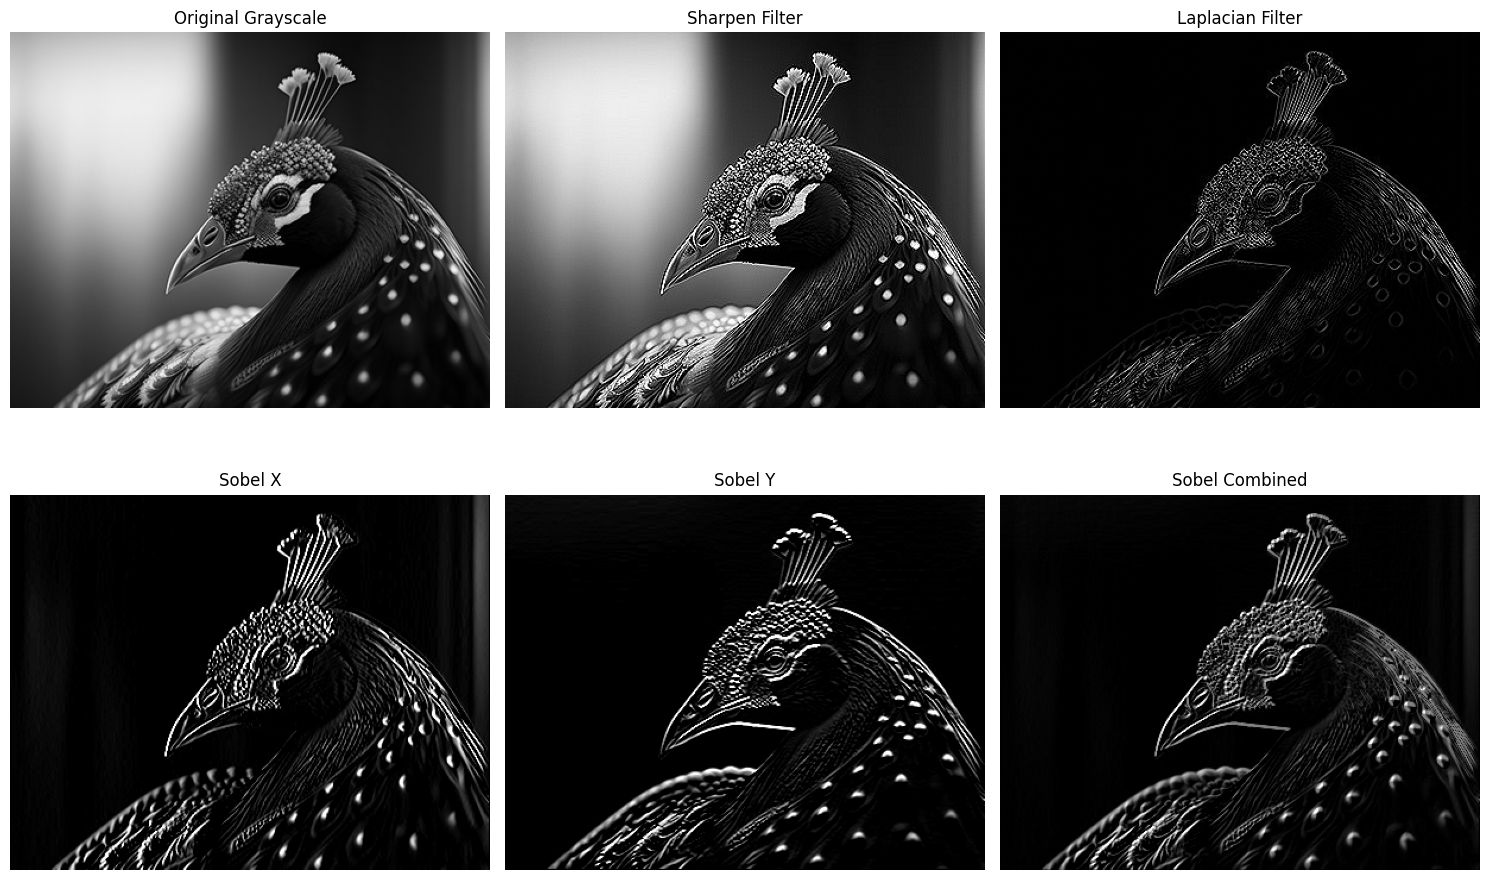

In [4]:
# TODO: Load an image (use OpenCV or matplotlib)

img=cv.imread(r'D:\AAST\SkyXperts\SkyXperts-Vision-Course\solved tasks\peacock.jpeg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
grey_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
sobel_x_kernel = np.array([[-1, 0, 1], 
                           [-2, 0, 2], 
                           [-1, 0, 1]])

sobel_y_kernel = np.array([[-1, -2, -1], 
                           [ 0,  0,  0], 
                           [ 1,  2,  1]])

laplacian_kernel = np.array([[0,  1, 0], 
                             [1, -4, 1], 
                             [0,  1, 0]])

sharpen_kernel = np.array([[ 0, -1,  0], 
                           [-1,  5, -1], 
                           [ 0, -1,  0]])

sobel_combined = cv.addWeighted(cv.filter2D(grey_img, -1, sobel_x_kernel), 0.5,
                                cv.filter2D(grey_img, -1, sobel_y_kernel), 0.5, 0)


sobel_x = cv.filter2D(grey_img, -1, sobel_x_kernel)
sobel_y = cv.filter2D(grey_img, -1, sobel_y_kernel)
laplacian = cv.filter2D(grey_img, -1, laplacian_kernel)
sharpen = cv.filter2D(grey_img, -1, sharpen_kernel)



fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Original Grayscale
axes[0, 0].imshow(grey_img, cmap='gray')
axes[0, 0].set_title('Original Grayscale')
axes[0, 0].axis('off')

# Sharpen
axes[0, 1].imshow(sharpen, cmap='gray')
axes[0, 1].set_title('Sharpen Filter')
axes[0, 1].axis('off')

# Laplacian
axes[0, 2].imshow(laplacian, cmap='gray')
axes[0, 2].set_title('Laplacian Filter')
axes[0, 2].axis('off')

# Sobel X
axes[1, 0].imshow(sobel_x, cmap='gray')
axes[1, 0].set_title('Sobel X')
axes[1, 0].axis('off')

# Sobel Y
axes[1, 1].imshow(sobel_y, cmap='gray')
axes[1, 1].set_title('Sobel Y')
axes[1, 1].axis('off')

axes[1, 2].imshow(sobel_combined, cmap='gray')
axes[1, 2].set_title('Sobel Combined')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Task 2: Build a Simple CNN on FashionMNIST
Construct and train a small Convolutional Neural Network (CNN) on the FashionMNIST dataset.

**Hint:**
- Use `torchvision.datasets.FashionMNIST` for loading data.
- Define a small CNN with `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.Linear`.
- Train for a few epochs using an optimizer (e.g., Adam) and loss function (e.g., CrossEntropyLoss).
- Print training accuracy after each epoch.

In [9]:

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
trainset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4, shuffle=True)


class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5) # input 1 channel, output 6 channels, kernel 5x5
        self.pool = nn.MaxPool2d(2, 2)
        # Image goes from 28x28 -> Conv(5x5) -> 24x24 -> Pool(2x2) -> 12x12
        # 6 channels * 12 width * 12 height
        self.fc1 = nn.Linear(6 * 12 * 12, 10) 

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        # Flatten the tensor for the fully connected layer
        x = x.view(-1, 6 * 12 * 12) 
        x = self.fc1(x)
        return x


net = SimpleCNN()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.001, momentum=0.9)


epochs=2
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[Epoch {epoch + 1}, Batch {i + 1}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
print('Finished Training')    

[Epoch 1, Batch 2000] loss: 0.705
[Epoch 1, Batch 4000] loss: 0.498
[Epoch 1, Batch 6000] loss: 0.432
[Epoch 1, Batch 8000] loss: 0.401
[Epoch 1, Batch 10000] loss: 0.375
[Epoch 1, Batch 12000] loss: 0.377
[Epoch 1, Batch 14000] loss: 0.391
[Epoch 2, Batch 2000] loss: 0.343
[Epoch 2, Batch 4000] loss: 0.357
[Epoch 2, Batch 6000] loss: 0.342
[Epoch 2, Batch 8000] loss: 0.354
[Epoch 2, Batch 10000] loss: 0.362
[Epoch 2, Batch 12000] loss: 0.334
[Epoch 2, Batch 14000] loss: 0.345
Finished Training


## Task 3: Visualize Feature Maps
Visualize feature maps produced by the first convolutional layer of your CNN.

**Hint:**
- Take a single image from the test set.
- Pass it through the first convolutional layer (`net.conv1`).
- Convert the output to NumPy and plot several channels as images.

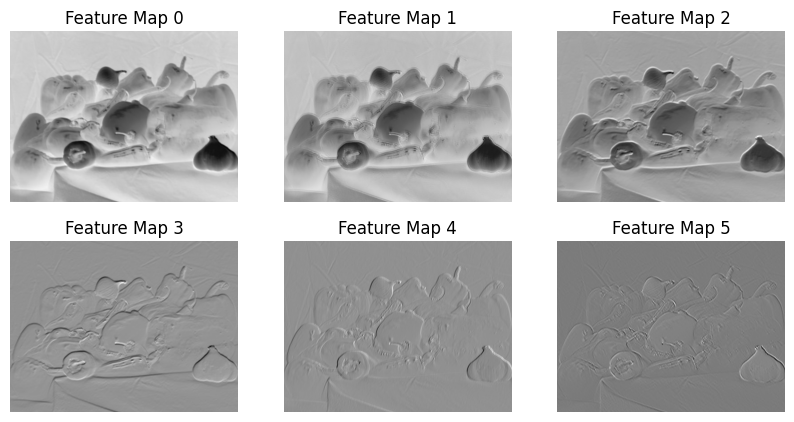

In [12]:
test_img = cv.imread(r"D:\AAST\SkyXperts\SkyXperts-Vision-Course\solved tasks\peppers.jpg")

#First Convo Layer (Conv1)
# Convert image to grayscale, apply transforms, add a batch dimension, and pass through conv1
conv1_output = net.conv1(transform(cv.cvtColor(test_img, cv.COLOR_BGR2GRAY)).unsqueeze(0))

# Convert the resulting tensor to a NumPy array for plotting
conv1_output_np = conv1_output.detach().numpy()


# Activation & Pooling ---
# Apply the ReLU activation function to the output of conv1 
conv1_activation = F.relu(conv1_output) 
conv1_activation = F.max_pool2d(conv1_activation, 2)


plt.figure(figsize=(10, 5))
for i in range(conv1_output_np.shape[1]): # Will loop 6 times since out_channels=6
    plt.subplot(2, 3, i + 1)
    plt.imshow(conv1_output_np[0, i], cmap='gray')
    plt.title(f'Feature Map {i}')
    plt.axis('off')
plt.show()

## Task 4: Haar Cascade Face Detection

Apply Haar Cascade classifiers for basic object detection (faces).

**Hint:**
- Use `cv2.CascadeClassifier` with a pre-trained XML file (e.g., `haarcascade_frontalface_default.xml`).
- Convert the input image to grayscale before detection.
- Use `detectMultiScale` to get bounding boxes.
- Draw rectangles on detected faces with `cv2.rectangle`.
- Visualize with Matplotlib.


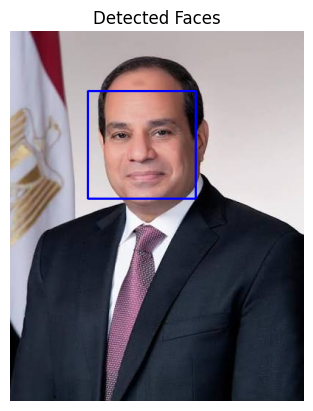

In [13]:
# TODO: Load an image containing a face
face=cv.imread(r"D:\AAST\SkyXperts\SkyXperts-Vision-Course\solved tasks\pres.jpg")
# TODO: Convert to grayscale
face_gray=cv.cvtColor(face, cv.COLOR_BGR2GRAY)
# TODO: Load Haar Cascade XML (frontal face) || cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
face_cascade=cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
# TODO: Apply detectMultiScale to find faces
faces=face_cascade.detectMultiScale(face_gray, 1.1, 4)
# TODO: Draw bounding boxes on the original image
for (x, y, w, h) in faces:
    cv.rectangle(face, (x, y), (x+w, y+h), (255, 0, 0), 2)
# TODO: Display results with matplotlib
import matplotlib.pyplot as plt
plt.imshow(cv.cvtColor(face, cv.COLOR_BGR2RGB))
plt.title('Detected Faces')
plt.axis('off')
plt.show()

